In [1]:

# ============================================================
# MACHINE LEARNING INTERNSHIP - WEEK 6 FINAL PROJECT
# Project: Car Price Prediction System
# ============================================================

!pip -q install kagglehub

import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

RANDOM_STATE = 42

print("Libraries installed and imported successfully!")


Libraries installed and imported successfully!


In [2]:

# Download the CarDekho vehicle dataset
dataset_path = kagglehub.dataset_download(
    "nehalbirla/vehicle-dataset-from-cardekho"
)

# Locate and load the CSV file
csv_path = os.path.join(dataset_path, "car data.csv")

df = pd.read_csv(csv_path)

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())


Using Colab cache for faster access to the 'vehicle-dataset-from-cardekho' dataset.
Dataset loaded successfully!
Number of rows and columns: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [3]:

print("Dataset Information")
print("=" * 50)

df.info()

print("\nMissing Values:")
display(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe(include="all").T)


Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Seller_Type    301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB

Missing Values:


,0
Car_Name,0
Year,0
Selling_Price,0
Present_Price,0
Kms_Driven,0
Fuel_Type,0
Seller_Type,0
Transmission,0
Owner,0



Duplicate Records: 2

Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Car_Name,301,98,city,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,301.0,NaN,NaN,NaN,2013.627907,2.891554,2003.0,2012.0,2014.0,2016.0,2018.0
Selling_Price,301.0,NaN,NaN,NaN,4.661296,5.082812,0.1,0.9,3.6,6.0,35.0
Present_Price,301.0,NaN,NaN,NaN,7.628472,8.644115,0.32,1.2,6.4,9.9,92.6
Kms_Driven,301.0,NaN,NaN,NaN,36947.20598,38886.883882,500.0,15000.0,32000.0,48767.0,500000.0
Fuel_Type,301,3,Petrol,239,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Seller_Type,301,2,Dealer,195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transmission,301,2,Manual,261,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Owner,301.0,NaN,NaN,NaN,0.043189,0.247915,0.0,0.0,0.0,0.0,3.0


In [4]:

# ============================================================
# CELL 4: DATA CLEANING AND PREPROCESSING
# ============================================================

data = df.copy()

# Clean column names
data.columns = data.columns.str.strip()

# Remove duplicate records
data.drop_duplicates(inplace=True)

# Define required columns
required_columns = [
    "Year",
    "Selling_Price",
    "Present_Price",
    "Kms_Driven",
    "Fuel_Type",
    "Seller_Type",
    "Transmission",
    "Owner"
]

# Validate dataset structure
missing_columns = set(required_columns) - set(data.columns)

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Convert numeric columns to numeric data types
numeric_columns = [
    "Year",
    "Selling_Price",
    "Present_Price",
    "Kms_Driven",
    "Owner"
]

for column in numeric_columns:
    data[column] = pd.to_numeric(
        data[column], errors="coerce"
    )

# Remove records with missing target or year
data.dropna(
    subset=["Selling_Price", "Year"],
    inplace=True
)

# Remove invalid prices, distances and years
CURRENT_YEAR = pd.Timestamp.now().year

data = data[
    (data["Selling_Price"] > 0) &
    (data["Present_Price"] > 0) &
    (data["Kms_Driven"] >= 0) &
    (data["Year"] > 1900) &
    (data["Year"] <= CURRENT_YEAR)
].copy()

# Feature engineering
data["Car_Age"] = CURRENT_YEAR - data["Year"]

# Select useful features
feature_columns = [
    "Present_Price",
    "Kms_Driven",
    "Fuel_Type",
    "Seller_Type",
    "Transmission",
    "Owner",
    "Car_Age"
]

X = data[feature_columns].copy()
y = data["Selling_Price"].copy()

# Clean categorical columns
categorical_columns = [
    "Fuel_Type",
    "Seller_Type",
    "Transmission"
]

for column in categorical_columns:
    X[column] = X[column].astype("string").str.strip()
    X[column] = X[column].replace("", pd.NA)

print("Data preprocessing completed successfully!")
print("Clean dataset shape:", data.shape)
print("Input features:", X.shape)
print("Target variable:", y.name)

display(data.head())


Data preprocessing completed successfully!
Clean dataset shape: (299, 10)
Input features: (299, 7)
Target variable: Selling_Price


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Car_Age
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0,12
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0,13
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0,9
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0,15
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0,12


In [5]:

# ============================================================
# CELL 5: TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training and testing split completed!")
print("-" * 45)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training percentage: 80%")
print("Testing percentage: 20%")


Training and testing split completed!
---------------------------------------------
Training records: 239
Testing records: 60
Training percentage: 80%
Testing percentage: 20%


In [6]:

# ============================================================
# CELL 6: PREPROCESSING PIPELINE
# ============================================================

numeric_features = [
    "Present_Price",
    "Kms_Driven",
    "Owner",
    "Car_Age"
]

categorical_features = [
    "Fuel_Type",
    "Seller_Type",
    "Transmission"
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        (
            "categorical",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [7]:

# ============================================================
# CELL 7: MODEL TRAINING
# ============================================================

models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

trained_models = {}
results = []

for model_name, estimator in models.items():

    model_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    # Train the model
    model_pipeline.fit(X_train, y_train)

    # Predict on unseen test records
    predictions = model_pipeline.predict(X_test)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, predictions)

    rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )

    r2 = r2_score(y_test, predictions)

    trained_models[model_name] = model_pipeline

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

print("All models trained successfully!")

display(results_df.round(4))


All models trained successfully!


,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.4729,2.5240,0.7528
1,Gradient Boosting,1.1390,2.5900,0.7397
2,Random Forest,1.4935,3.5692,0.5057


In [8]:

# ============================================================
# CELL 8: BEST MODEL SELECTION
# ============================================================

best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]

best_predictions = best_model.predict(X_test)

best_mae = mean_absolute_error(
    y_test, best_predictions
)

best_rmse = np.sqrt(
    mean_squared_error(y_test, best_predictions)
)

best_r2 = r2_score(
    y_test, best_predictions
)

print("=" * 55)
print("BEST PERFORMING MODEL")
print("=" * 55)
print("Model:", best_model_name)
print(f"Mean Absolute Error (MAE): {best_mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {best_rmse:.4f}")
print(f"R-squared (R2): {best_r2:.4f}")
print("=" * 55)


BEST PERFORMING MODEL
Model: Linear Regression
Mean Absolute Error (MAE): 1.4729
Root Mean Squared Error (RMSE): 2.5240
R-squared (R2): 0.7528


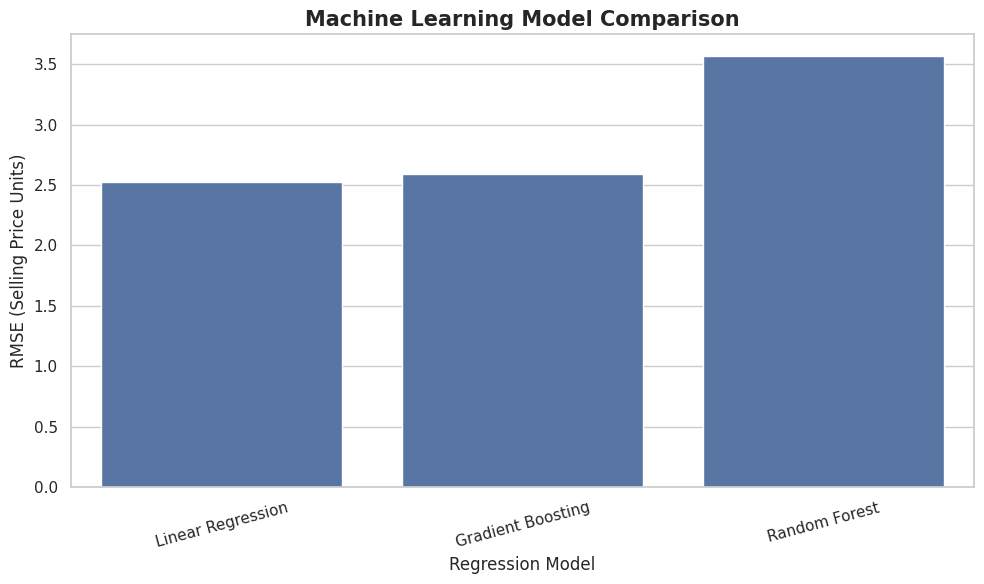

In [9]:

# ============================================================
# CELL 9: MODEL COMPARISON CHART
# ============================================================

plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE"
)

plt.title(
    "Machine Learning Model Comparison",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Regression Model")
plt.ylabel("RMSE (Selling Price Units)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


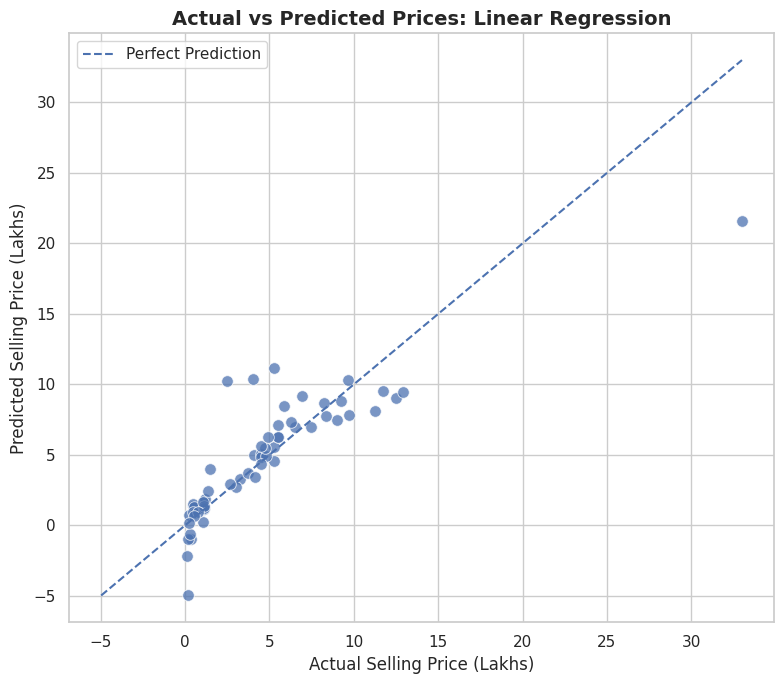

In [10]:

# ============================================================
# CELL 10: ACTUAL VS PREDICTED VISUALIZATION
# ============================================================

plt.figure(figsize=(8, 7))

sns.scatterplot(
    x=np.asarray(y_test),
    y=best_predictions,
    s=70,
    alpha=0.75
)

minimum = min(
    np.asarray(y_test).min(),
    best_predictions.min()
)

maximum = max(
    np.asarray(y_test).max(),
    best_predictions.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    label="Perfect Prediction"
)

plt.title(
    f"Actual vs Predicted Prices: {best_model_name}",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Actual Selling Price (Lakhs)")
plt.ylabel("Predicted Selling Price (Lakhs)")
plt.legend()
plt.tight_layout()
plt.show()


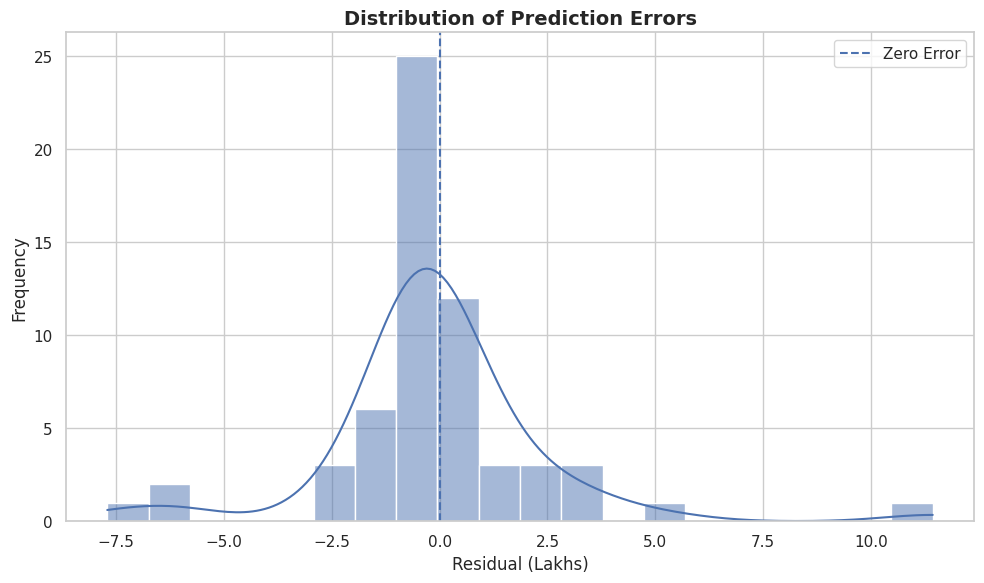

Mean residual: -0.0768


In [11]:

# ============================================================
# CELL 11: RESIDUAL ERROR ANALYSIS
# ============================================================

residuals = (
    np.asarray(y_test) - best_predictions
)

plt.figure(figsize=(10, 6))

sns.histplot(
    residuals,
    bins=20,
    kde=True
)

plt.axvline(
    0,
    linestyle="--",
    label="Zero Error"
)

plt.title(
    "Distribution of Prediction Errors",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Residual (Lakhs)")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

print("Mean residual:", round(residuals.mean(), 4))


,Actual Price,Predicted Price,Absolute Error
0,8.99,7.502,1.488
1,8.35,7.792,0.558
2,0.45,1.366,0.916
3,7.45,7.009,0.441
4,5.25,11.163,5.913
5,5.25,4.534,0.716
6,5.85,8.492,2.642
7,1.15,1.701,0.551
8,9.25,8.824,0.426
9,0.38,-0.963,1.343


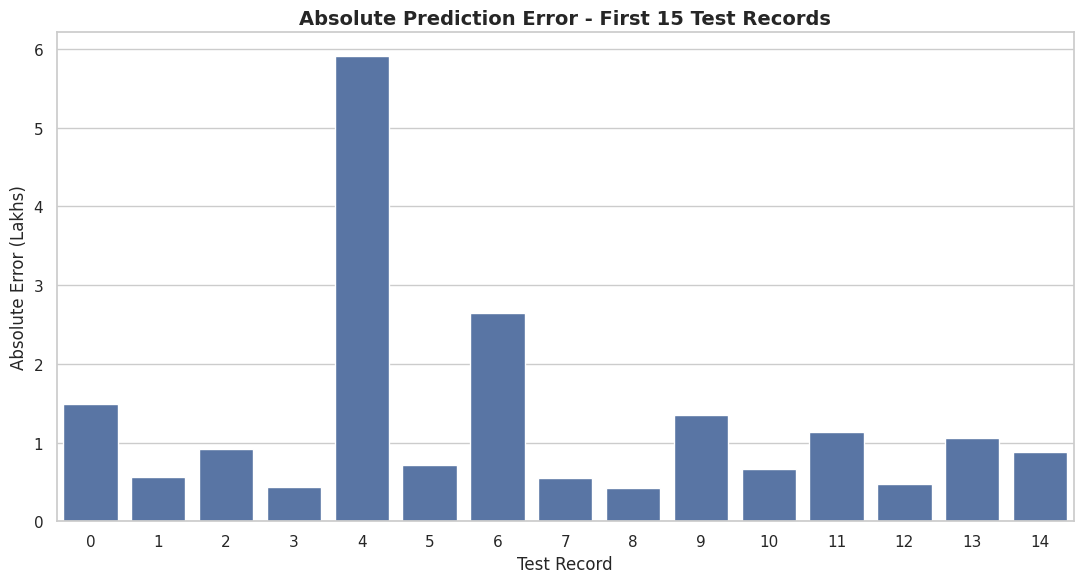

In [12]:

# ============================================================
# CELL 12: PREDICTION ERROR ANALYSIS
# ============================================================

error_df = pd.DataFrame({
    "Actual Price": np.asarray(y_test),
    "Predicted Price": best_predictions,
    "Absolute Error": np.abs(residuals)
}).reset_index(drop=True)

display(error_df.head(15).round(3))

plt.figure(figsize=(11, 6))

plot_data = error_df.head(15)

sns.barplot(
    x=plot_data.index,
    y=plot_data["Absolute Error"]
)

plt.title(
    "Absolute Prediction Error - First 15 Test Records",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Test Record")
plt.ylabel("Absolute Error (Lakhs)")
plt.tight_layout()
plt.show()


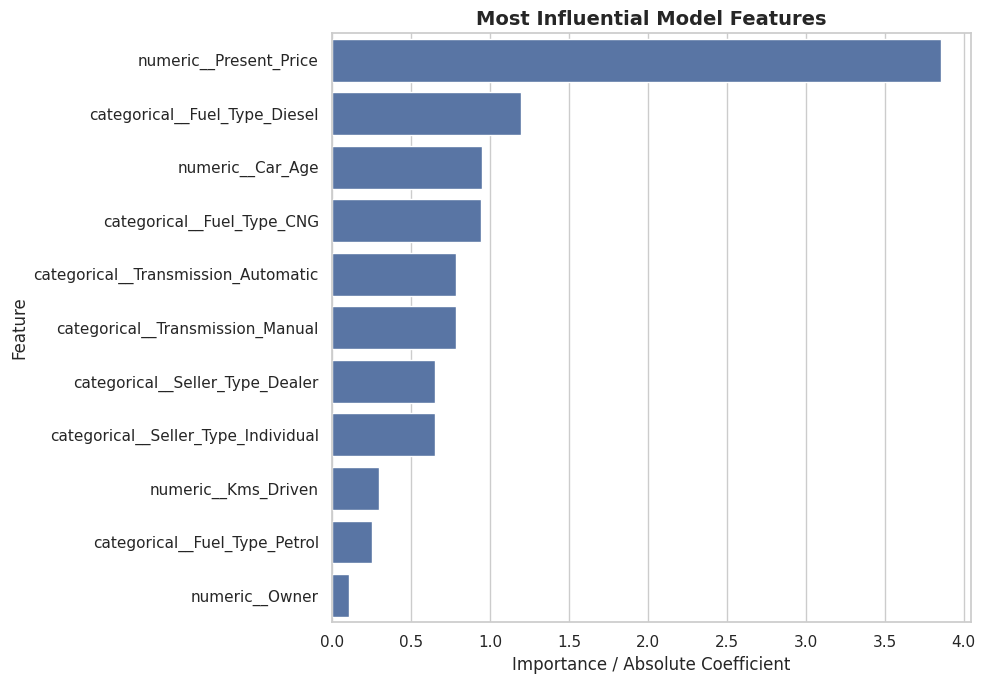

,Feature,Importance
0,numeric__Present_Price,3.8548
5,categorical__Fuel_Type_Diesel,1.1959
3,numeric__Car_Age,0.9511
4,categorical__Fuel_Type_CNG,0.9432
9,categorical__Transmission_Automatic,0.7861
10,categorical__Transmission_Manual,0.7861
7,categorical__Seller_Type_Dealer,0.6507
8,categorical__Seller_Type_Individual,0.6507
1,numeric__Kms_Driven,0.2962
6,categorical__Fuel_Type_Petrol,0.2526


In [13]:

# ============================================================
# CELL 13: FEATURE IMPORTANCE ANALYSIS
# ============================================================

fitted_preprocessor = best_model.named_steps["preprocessor"]
fitted_estimator = best_model.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()

if hasattr(fitted_estimator, "feature_importances_"):

    importance_values = fitted_estimator.feature_importances_

elif hasattr(fitted_estimator, "coef_"):

    importance_values = np.abs(
        np.asarray(fitted_estimator.coef_).ravel()
    )

else:
    importance_values = None

if importance_values is not None:

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance_values
    })

    importance_df = importance_df.sort_values(
        by="Importance",
        ascending=False
    ).head(12)

    plt.figure(figsize=(10, 7))

    sns.barplot(
        data=importance_df,
        x="Importance",
        y="Feature"
    )

    plt.title(
        "Most Influential Model Features",
        fontsize=14,
        fontweight="bold"
    )

    plt.xlabel("Importance / Absolute Coefficient")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()

    display(importance_df.round(4))

else:
    print("Feature importance is unavailable for this model.")


In [14]:

# ============================================================
# CELL 14: CAR PRICE PREDICTION FUNCTION
# ============================================================

def predict_car_price(
    present_price,
    year,
    kms_driven,
    fuel_type,
    seller_type,
    transmission,
    owner
):
    """Predict a used car's selling price in lakhs."""

    current_year = pd.Timestamp.now().year

    # Validate input
    if not 1901 <= int(year) <= current_year:
        raise ValueError(
            f"Year must be between 1901 and {current_year}."
        )

    if float(present_price) <= 0:
        raise ValueError(
            "Present price must be greater than zero."
        )

    if float(kms_driven) < 0:
        raise ValueError(
            "Kilometers driven cannot be negative."
        )

    if int(owner) < 0:
        raise ValueError(
            "Owner count cannot be negative."
        )

    # Create input record
    input_data = pd.DataFrame([{
        "Present_Price": float(present_price),
        "Kms_Driven": float(kms_driven),
        "Fuel_Type": str(fuel_type).strip(),
        "Seller_Type": str(seller_type).strip(),
        "Transmission": str(transmission).strip(),
        "Owner": int(owner),
        "Car_Age": current_year - int(year)
    }], columns=feature_columns)

    # Generate prediction
    predicted_price = float(
        best_model.predict(input_data)[0]
    )

    # Return non-negative estimate
    return max(0.0, predicted_price)


print("Car price prediction function created successfully!")


Car price prediction function created successfully!


In [15]:

# ============================================================
# CELL 15: SAMPLE PREDICTION
# ============================================================

sample_prediction = predict_car_price(
    present_price=8.5,
    year=2020,
    kms_driven=35000,
    fuel_type="Petrol",
    seller_type="Dealer",
    transmission="Manual",
    owner=0
)

print("=" * 50)
print("       SAMPLE CAR PRICE PREDICTION")
print("=" * 50)
print("Selected model:", best_model_name)
print(f"Estimated selling price: {sample_prediction:.2f} lakhs")
print("=" * 50)


       SAMPLE CAR PRICE PREDICTION
Selected model: Linear Regression
Estimated selling price: 7.11 lakhs


In [16]:

# ============================================================
# CELL 16: INTERACTIVE USER INPUT SYSTEM
# ============================================================

print("=" * 55)
print("          CAR PRICE PREDICTION SYSTEM")
print("=" * 55)

try:
    present_price = float(
        input("Present showroom price (lakhs): ")
    )

    year = int(
        input("Manufacturing year: ")
    )

    kms_driven = float(
        input("Kilometers driven: ")
    )

    print("\nFuel options: Petrol, Diesel, CNG")
    fuel_type = input("Fuel type: ").strip().title()

    print("\nSeller options: Dealer, Individual")
    seller_type = input("Seller type: ").strip().title()

    print("\nTransmission options: Manual, Automatic")
    transmission = input("Transmission type: ").strip().title()

    owner = int(
        input("Number of previous owners (0, 1, 2, etc.): ")
    )

    predicted_price = predict_car_price(
        present_price=present_price,
        year=year,
        kms_driven=kms_driven,
        fuel_type=fuel_type,
        seller_type=seller_type,
        transmission=transmission,
        owner=owner
    )

    print("\n" + "=" * 55)
    print("                PREDICTION RESULT")
    print("=" * 55)
    print("Selected model:", best_model_name)
    print(f"Predicted selling price: {predicted_price:.2f} lakhs")
    print("=" * 55)

except ValueError as error:
    print("Invalid input:", error)


          CAR PRICE PREDICTION SYSTEM
Present showroom price (lakhs): 5000000
Manufacturing year: 2020
Kilometers driven: 50

Fuel options: Petrol, Diesel, CNG
Fuel type: petrol

Seller options: Dealer, Individual
Seller type: Dealer

Transmission options: Manual, Automatic
Transmission type: AUtomatic
Number of previous owners (0, 1, 2, etc.): 0

                PREDICTION RESULT
Selected model: Linear Regression
Predicted selling price: 2185939.04 lakhs


In [17]:

# ============================================================
# CELL 17: SAVE MODEL AND RESULTS
# ============================================================

output_dir = "car_price_prediction_output"
os.makedirs(output_dir, exist_ok=True)

# Save complete trained pipeline
model_path = os.path.join(
    output_dir,
    "best_car_price_model.joblib"
)

joblib.dump(best_model, model_path)

# Save evaluation metrics
results_path = os.path.join(
    output_dir,
    "model_evaluation_results.csv"
)

results_df.to_csv(
    results_path,
    index=False
)

# Save test predictions
predictions_path = os.path.join(
    output_dir,
    "test_predictions.csv"
)

error_df.to_csv(
    predictions_path,
    index=False
)

print("Project files saved successfully!")
print("Model:", model_path)
print("Evaluation:", results_path)
print("Predictions:", predictions_path)


Project files saved successfully!
Model: car_price_prediction_output/best_car_price_model.joblib
Evaluation: car_price_prediction_output/model_evaluation_results.csv
Predictions: car_price_prediction_output/test_predictions.csv


In [18]:

# ============================================================
# CELL 18: LOAD AND VERIFY SAVED MODEL
# ============================================================

loaded_model = joblib.load(model_path)

verification_input = pd.DataFrame([{
    "Present_Price": 8.5,
    "Kms_Driven": 35000,
    "Fuel_Type": "Petrol",
    "Seller_Type": "Dealer",
    "Transmission": "Manual",
    "Owner": 0,
    "Car_Age": pd.Timestamp.now().year - 2020
}], columns=feature_columns)

verification_prediction = loaded_model.predict(
    verification_input
)[0]

print("Saved model loaded successfully!")
print(
    f"Verification prediction: "
    f"{max(0.0, verification_prediction):.2f} lakhs"
)


Saved model loaded successfully!
Verification prediction: 7.11 lakhs
